# fiss_planner quick start

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SS47816/fiss_planner/blob/main/examples/quickstart.ipynb)

This notebook plans around a parked car on a curved two-lane road:
1. with each of the four planners (FOP, FOP+, FISS, FISS+), comparing how many trajectories they explore;
2. in closed loop with `LocalPlanner`, the full pipeline used by the ROS nodes.

In [1]:
import importlib.util
import subprocess
import sys

if importlib.util.find_spec("fiss_planner") is None:  # e.g. on Colab
    pip = [sys.executable, "-m", "pip", "install", "-q"]
    if subprocess.call(pip + ["fiss-planner"]) != 0:  # no wheel yet: build from source (~2 min)
        subprocess.check_call(pip + ["git+https://github.com/SS47816/fiss_planner"])

In [2]:
import fiss_planner as fp
import matplotlib.pyplot as plt
import numpy as np

print("fiss_planner", fp.__version__)

fiss_planner 1.0.0


## A road, its lanes and an obstacle

The reference line can be any polyline; the corridor holds the lanes the planner may use, as lateral
offsets from it. Obstacles carry their own time-stamped predictions.

In [3]:
x = np.linspace(0.0, 300.0, 61)
y = 8.0 * np.sin(x / 60.0)
road = fp.ReferenceLine(x, y)
lanes = fp.Corridor.parallel_lanes(0.0, road.length, 3.5, 1, 0)  # ego lane + one lane to the left

# A car stopped in the ego lane 45 m ahead (constant-velocity prediction at 0 m/s).
p = road.at(45.0)
parked = fp.predict_constant_velocity(1, p.x, p.y, p.yaw, 0.0, 4.5, 1.9, horizon=6.0, dt=0.1)

start = fp.FrenetState(s=10.0, s_d=10.0)  # 10 m along the road at 10 m/s

## Four planners, one interface

All four share sampling, costs and validation; they differ only in how they search the grid of end states.

In [4]:
results = {}
for name in ["fop", "fop_plus", "fiss", "fiss_plus"]:
    cfg = fp.make_config(name)
    cfg.keep_candidates = True  # keep every generated trajectory for plotting
    planner = fp.make_planner(cfg)
    planner.plan(start, road, lanes, [parked], target_speed=12.0)  # warm-up
    results[name] = planner.plan(start, road, lanes, [parked], target_speed=12.0)

print(f"{'planner':10s} {'success':>7s} {'lane':>4s} {'generated':>9s} {'time':>8s}")
for name, r in results.items():
    s = r.stats
    print(f"{name:10s} {str(r.success):>7s} {r.trajectory.lane:4d} {s.num_generated:9d} {s.time_ms:6.2f} ms")

planner    success lane generated     time
fop           True    1       250   2.79 ms
fop_plus      True    1       250   1.91 ms
fiss          True    1         7   0.10 ms
fiss_plus     True    1        35   0.37 ms


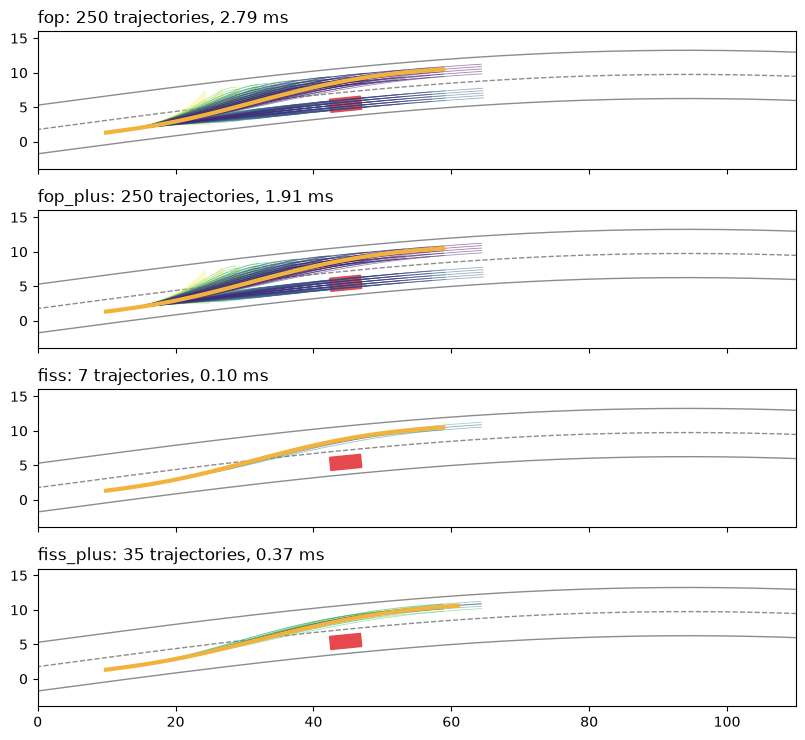

In [5]:
def draw_scene(ax, x_max):
    s = np.linspace(0.0, road.length, 300)
    pts = [road.at(si) for si in s]
    cx, cy = np.array([q.x for q in pts]), np.array([q.y for q in pts])
    yaw = np.array([q.yaw for q in pts])
    for off, style in [(-1.75, "-"), (1.75, "--"), (5.25, "-")]:
        ax.plot(cx - off * np.sin(yaw), cy + off * np.cos(yaw), style, color="0.55", lw=1)
    box = np.asarray(fp.Box2d(p.x, p.y, p.yaw, 4.5, 1.9).corners())
    ax.fill(box[:, 0], box[:, 1], color="#e5484d")
    ax.set_xlim(0, x_max)
    ax.set_ylim(-4, 16)
    ax.set_aspect("equal")


fig, axes = plt.subplots(4, 1, figsize=(10, 7.5), sharex=True)
for ax, (name, r) in zip(axes, results.items()):
    draw_scene(ax, 110)
    cands = sorted(r.candidates, key=lambda c: c.total_cost(), reverse=True)  # cheapest drawn last
    for k, c in enumerate(cands):
        ax.plot(c.x, c.y, color=plt.cm.viridis_r(k / max(1, len(cands) - 1)), lw=0.6, alpha=0.5)
    ax.plot(r.trajectory.x, r.trajectory.y, color="#f2b33d", lw=3)
    ax.set_title(f"{name}: {r.stats.num_generated} trajectories, {r.stats.time_ms:.2f} ms", loc="left")
fig.tight_layout()

## Closed loop with `LocalPlanner`

`LocalPlanner.step()` runs the whole pipeline each cycle: stitching to the previous plan, speed policy,
planning, optional smoothing and fail-safes. Here the ego follows each plan perfectly for one 0.1 s
step; in a real stack a controller (`fp.make_controller("mpc")`) closes the loop.

mean planning time 0.12 ms over 140 cycles


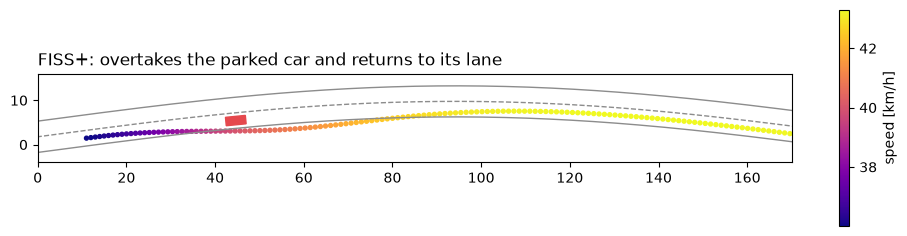

In [6]:
cfg = fp.LocalPlannerConfig()
cfg.planner = fp.make_config("fiss_plus")
cfg.desired_speed = 12.0
lp = fp.LocalPlanner(cfg)
lp.set_reference_path(x, y)

ego = fp.EgoState(x[2], y[2], np.arctan2(y[3] - y[2], x[3] - x[2]), v=10.0)
log = []
for k in range(140):
    out = lp.step(k * 0.1, ego, [parked])
    nxt = out.trajectory.sample(0.1)
    ego = fp.EgoState(nxt.x, nxt.y, nxt.yaw, v=nxt.v, a=nxt.a, kappa=nxt.kappa)
    log.append((ego.x, ego.y, ego.v, out.stats.time_ms))
log = np.array(log)

fig, ax = plt.subplots(figsize=(10, 3))
draw_scene(ax, 170)
sc = ax.scatter(log[:, 0], log[:, 1], c=log[:, 2] * 3.6, s=8, cmap="plasma")
fig.colorbar(sc, ax=ax, label="speed [km/h]", shrink=0.8)
ax.set_title("FISS+: overtakes the parked car and returns to its lane", loc="left")
fig.tight_layout()
print(f"mean planning time {log[:, 3].mean():.2f} ms over {len(log)} cycles")

## Next steps

- Real maps: `fp.RoadMap` with `LocalPlanner.set_map()`, or the Lanelet2 adapter in the ROS packages.
- Benchmarks: `python -m fiss_planner.commonroad.benchmark` (CommonRoad) and `python -m fiss_planner.carla.closed_loop` (CARLA).
- Documentation: <https://ss47816.github.io/fiss_planner/>